In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize']=(10,6)

### LOAD  DATASET


In [2]:
df = pd.read_csv("civilian_firearms_2017.csv")

print(df.shape)
df.head()

(230, 10)


,location,iso3,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017,sas_region,sas_subregion,computation_method
0,United States,USA,120.5,393347000,1073743.0,392273257.0,326474000,Americas,North America,survey and expert estimate
1,Falkland Islands,FLK,62.1,2000,1705.0,295.0,3000,Americas,South America,expert estimate
2,Yemen,YEM,52.8,14859000,NaN,NaN,28120000,Asia,Western Asia,expert estimate
3,New Caledonia,NCL,42.5,115000,55000.0,60000.0,270000,Oceania,Melanesia,expert estimate
4,Serbia,SRB,39.1,2719000,1186086.0,1532914.0,6946000,Europe,Southern Europe,expert estimate


##  Basic Exploration

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 230 entries, 0 to 229
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   location                 230 non-null    str    
 1   iso3                     230 non-null    str    
 2   firearms_per_100_people  230 non-null    float64
 3   civilian_firearms        230 non-null    int64  
 4   registered_firearms      136 non-null    float64
 5   unregistered_firearms    136 non-null    float64
 6   population_2017          230 non-null    int64  
 7   sas_region               230 non-null    str    
 8   sas_subregion            230 non-null    str    
 9   computation_method       230 non-null    str    
dtypes: float64(3), int64(2), str(5)
memory usage: 28.8 KB


In [4]:
df.describe()

,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017
count,230.000000,2.300000e+02,1.360000e+02,1.360000e+02,2.300000e+02
mean,9.873783,3.734467e+06,7.369254e+05,5.039537e+06,3.268730e+07
std,12.514074,2.672093e+07,1.591265e+06,3.431796e+07,1.321560e+08
min,0.000000,0.000000e+00,4.800000e+01,5.000000e+01,1.000000e+03
25%,2.100000,3.150000e+04,1.647000e+04,5.616750e+04,6.060000e+05
50%,5.900000,2.400000e+05,1.421490e+05,2.533020e+05,5.522000e+06
75%,13.675000,1.042500e+06,5.419222e+05,8.390662e+05,2.048825e+07
max,120.500000,3.933470e+08,9.700000e+06,3.922733e+08,1.388233e+09


In [5]:
df.isnull().sum()

location                    0
iso3                        0
firearms_per_100_people     0
civilian_firearms           0
registered_firearms        94
unregistered_firearms      94
population_2017             0
sas_region                  0
sas_subregion               0
computation_method          0
dtype: int64

## Duplicate Records

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.drop_duplicates(inplace=True)

## Missing Values

In [9]:
df.isnull().sum()

location                    0
iso3                        0
firearms_per_100_people     0
civilian_firearms           0
registered_firearms        94
unregistered_firearms      94
population_2017             0
sas_region                  0
sas_subregion               0
computation_method          0
dtype: int64

In [10]:
df.fillna(0,inplace=True)

,location,iso3,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017,sas_region,sas_subregion,computation_method
0,United States,USA,120.50,393347000,1073743.0,392273257.0,326474000,Americas,North America,survey and expert estimate
1,Falkland Islands,FLK,62.10,2000,1705.0,295.0,3000,Americas,South America,expert estimate
2,Yemen,YEM,52.80,14859000,0.0,0.0,28120000,Asia,Western Asia,expert estimate
3,New Caledonia,NCL,42.50,115000,55000.0,60000.0,270000,Oceania,Melanesia,expert estimate
4,Serbia,SRB,39.10,2719000,1186086.0,1532914.0,6946000,Europe,Southern Europe,expert estimate
...,...,...,...,...,...,...,...,...,...,...
225,Taiwan,TWN,0.04,10000,5000.0,5000.0,23405000,Asia,East Asia,expert estimate
226,Indonesia,IDN,0.03,82000,41102.0,40898.0,263510000,Asia,South-East Asia,expert estimate
227,Nauru,NRU,0.00,0,0.0,0.0,10000,Oceania,Melanesia,expert estimate
228,Christmas Island,CXR,0.00,0,0.0,0.0,2000,Asia,South-East Asia,expert estimate


## Display Dataset

In [11]:
df.sample(10)

,location,iso3,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017,sas_region,sas_subregion,computation_method
121,Estonia,EST,5.0,65000,47000.0,18000.0,1306000,Europe,Northern Europe,survey and expert estimate
219,North Korea,PRK,0.3,76000,0.0,0.0,25405000,Asia,East Asia,analogous comparison
53,San Marino,SMR,14.4,5000,0.0,0.0,32000,Europe,Southern Europe,analogous comparison
218,Japan,JPN,0.3,377000,175221.0,201779.0,126045000,Asia,East Asia,expert estimate
222,Timor-Leste,TLS,0.3,3000,0.0,0.0,1237000,Asia,South-East Asia,expert estimate
133,Egypt,EGY,4.1,3931000,250000.0,3681000.0,95215000,Africa,North Africa,expert estimate
40,Paraguay,PRY,16.7,1140000,392000.0,748000.0,6812000,Americas,South America,expert estimate
189,Tunisia,TUN,1.1,123000,3408.0,119592.0,11495000,Africa,North Africa,analogous comparison
216,Uzbekistan,UZB,0.4,127000,0.0,0.0,30691000,Asia,Central Asia,analogous comparison
195,Bhutan,BTN,0.8,6000,4309.0,1691.0,793000,Asia,South Asia,analogous comparison


## Top 10 Countries by Firearms Per 100 People

In [12]:
top10_rate = df.sort_values(
    "firearms_per_100_people",
    ascending=False
).head(10)

top10_rate[["location","firearms_per_100_people"]]

,location,firearms_per_100_people
0,United States,120.5
1,Falkland Islands,62.1
2,Yemen,52.8
3,New Caledonia,42.5
4,Serbia,39.1
5,Montenegro,39.1
6,Canada,34.7
7,Uruguay,34.7
8,Cyprus,34.0
9,Finland,32.4


## Visualization:

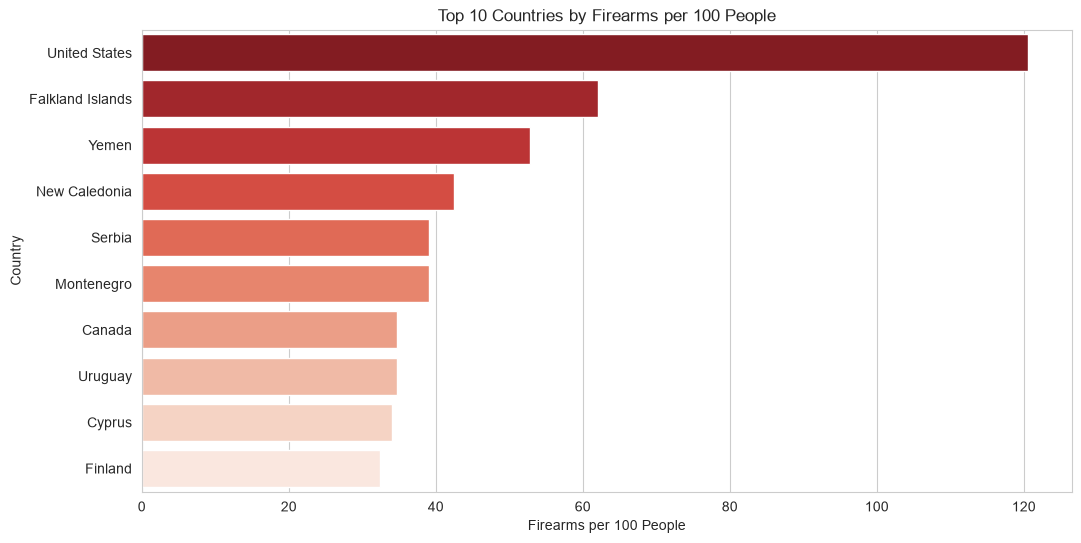

In [13]:
plt.figure(figsize=(12,6))

sns.barplot(
    x="firearms_per_100_people",
    y="location",
    data=top10_rate,
    palette="Reds_r"
)

plt.title("Top 10 Countries by Firearms per 100 People")
plt.xlabel("Firearms per 100 People")
plt.ylabel("Country")

plt.show()

## Top 10 Countries by Total Civilian Firearms

In [14]:
top10_total = df.sort_values(
    "civilian_firearms",
    ascending=False
).head(10)

top10_total[
    ["location","civilian_firearms"]
]

,location,civilian_firearms
0,United States,393347000
119,India,71101000
138,China,49735000
24,Pakistan,43917000
67,Russia,17620000
96,Brazil,17510000
60,Mexico,16809000
28,Germany,15822000
2,Yemen,14859000
45,Turkey,13249000


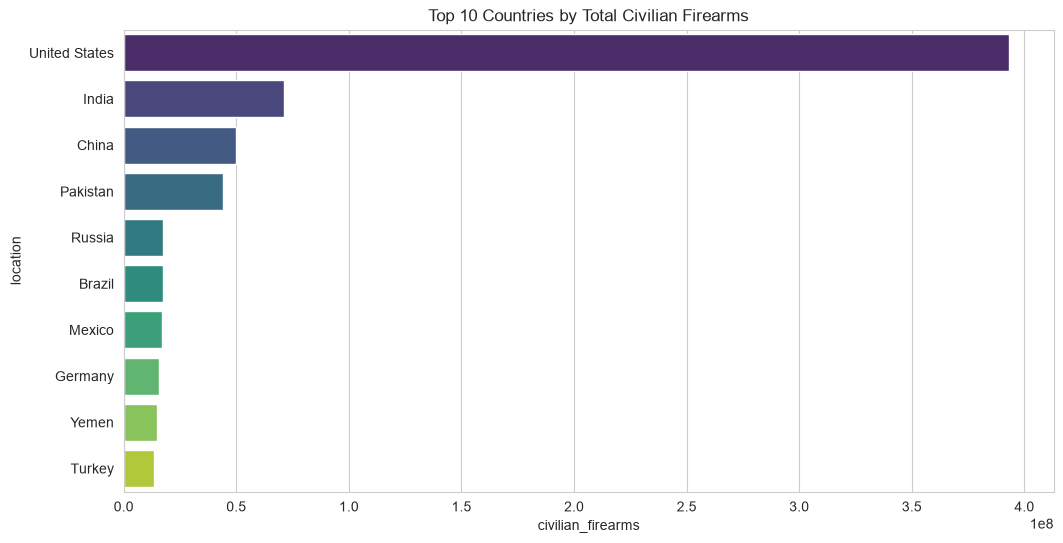

In [15]:
plt.figure(figsize=(12,6))

sns.barplot(
    x="civilian_firearms",
    y="location",
    data=top10_total,
    palette="viridis"
)

plt.title("Top 10 Countries by Total Civilian Firearms")

plt.show()

##  Bottom 10 Countries

In [16]:
bottom10 = df.sort_values(
    "firearms_per_100_people"
).head(10)

bottom10[
    ["location","firearms_per_100_people"]
]

,location,firearms_per_100_people
227,Nauru,0.00
228,Christmas Island,0.00
229,Holy See,0.00
226,Indonesia,0.03
225,Taiwan,0.04
223,South Korea,0.20
224,Solomon Islands,0.20
222,Timor-Leste,0.30
217,Benin,0.30
220,Malawi,0.30


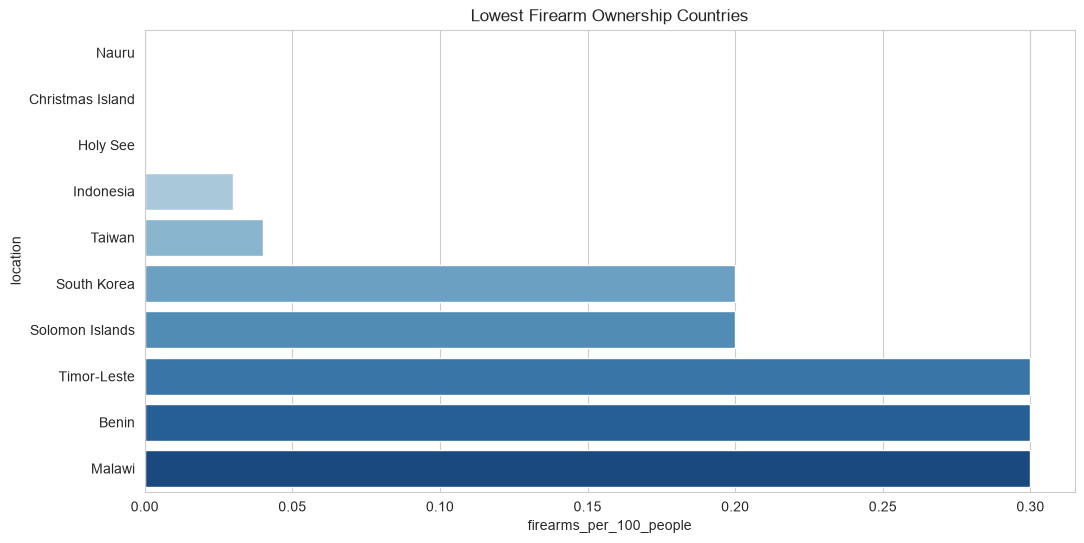

In [17]:
plt.figure(figsize=(12,6))

sns.barplot(
    x="firearms_per_100_people",
    y="location",
    data=bottom10,
    palette="Blues"
)

plt.title("Lowest Firearm Ownership Countries")

plt.show()


## Regional Analysis

In [18]:
region_analysis = df.groupby(
    "sas_region"
)["firearms_per_100_people"].mean().sort_values(
    ascending=False
)

region_analysis

sas_region
Europe      16.075000
Americas    12.770588
Asia         7.966078
Oceania      6.736842
Africa       4.377193
Name: firearms_per_100_people, dtype: float64

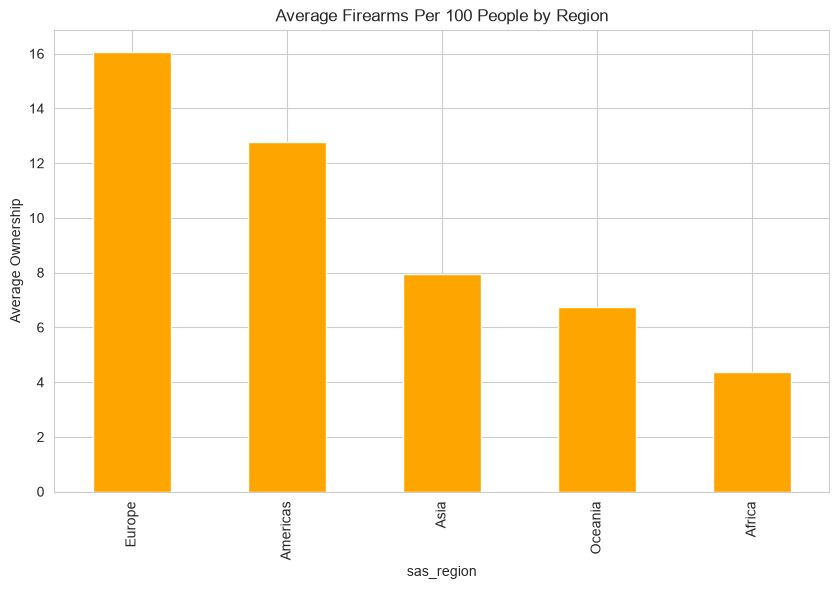

In [19]:
region_analysis.plot(
    kind="bar",
    color="orange"
)

plt.title("Average Firearms Per 100 People by Region")
plt.ylabel("Average Ownership")

plt.show()

##  Sub-Region Analysis

In [20]:
subregion_analysis = (
    df.groupby("sas_subregion")
    ["firearms_per_100_people"]
    .mean()
    .sort_values(ascending=False)
)

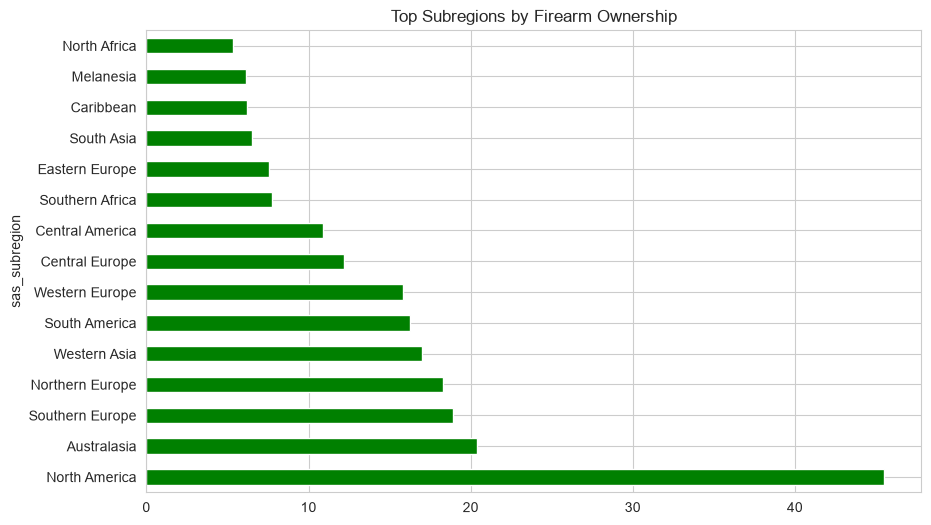

In [21]:
subregion_analysis.head(15).plot(
    kind='barh',
    color='green'
)

plt.title("Top Subregions by Firearm Ownership")
plt.show()

##  Registered vs Unregistered Firearms

In [22]:
df["registered_pct"] = (
    df["registered_firearms"] /
    df["civilian_firearms"]
)*100

df["unregistered_pct"] = (
    df["unregistered_firearms"] /
    df["civilian_firearms"]
)*100


## Handle infinity:

In [23]:
df.replace(
    [np.inf,-np.inf],
    np.nan,
    inplace=True
)

df.fillna(0,inplace=True)

,location,iso3,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017,sas_region,sas_subregion,computation_method,registered_pct,unregistered_pct
0,United States,USA,120.50,393347000,1073743.0,392273257.0,326474000,Americas,North America,survey and expert estimate,0.272976,99.727024
1,Falkland Islands,FLK,62.10,2000,1705.0,295.0,3000,Americas,South America,expert estimate,85.250000,14.750000
2,Yemen,YEM,52.80,14859000,0.0,0.0,28120000,Asia,Western Asia,expert estimate,0.000000,0.000000
3,New Caledonia,NCL,42.50,115000,55000.0,60000.0,270000,Oceania,Melanesia,expert estimate,47.826087,52.173913
4,Serbia,SRB,39.10,2719000,1186086.0,1532914.0,6946000,Europe,Southern Europe,expert estimate,43.622140,56.377860
...,...,...,...,...,...,...,...,...,...,...,...,...
225,Taiwan,TWN,0.04,10000,5000.0,5000.0,23405000,Asia,East Asia,expert estimate,50.000000,50.000000
226,Indonesia,IDN,0.03,82000,41102.0,40898.0,263510000,Asia,South-East Asia,expert estimate,50.124390,49.875610
227,Nauru,NRU,0.00,0,0.0,0.0,10000,Oceania,Melanesia,expert estimate,0.000000,0.000000
228,Christmas Island,CXR,0.00,0,0.0,0.0,2000,Asia,South-East Asia,expert estimate,0.000000,0.000000


Top Registered Countries:

In [24]:
top_registered = df.sort_values(
    "registered_pct",
    ascending=False
).head(10)

top_registered[
    ["location","registered_pct"]
]

,location,registered_pct
20,New Zealand,99.009901
51,Australia,88.407361
9,Finland,86.023201
1,Falkland Islands,85.250000
22,Sweden,85.168902
16,Norway,81.629018
17,Malta,81.029412
37,Northern Cyprus,80.560656
110,Slovakia,78.873239
32,Luxembourg,78.181818


Visualization:

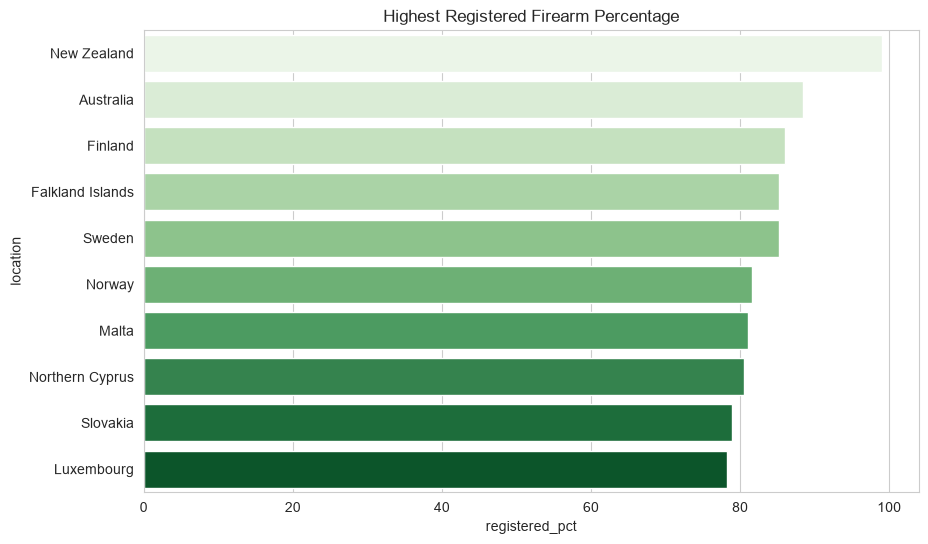

In [25]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="registered_pct",
    y="location",
    data=top_registered,
    palette="Greens"
)

plt.title("Highest Registered Firearm Percentage")

plt.show()

## Correlation Analysis

In [26]:
corr = df[
    [
        "firearms_per_100_people",
        "civilian_firearms",
        "registered_firearms",
        "unregistered_firearms",
        "population_2017"
    ]
].corr()

corr

,firearms_per_100_people,civilian_firearms,registered_firearms,unregistered_firearms,population_2017
firearms_per_100_people,1.000000,0.592505,0.159839,0.580450,0.030886
civilian_firearms,0.592505,1.000000,0.222639,0.997736,0.362773
registered_firearms,0.159839,0.222639,1.000000,0.180760,0.467286
unregistered_firearms,0.580450,0.997736,0.180760,1.000000,0.342496
population_2017,0.030886,0.362773,0.467286,0.342496,1.000000


Heatmap:

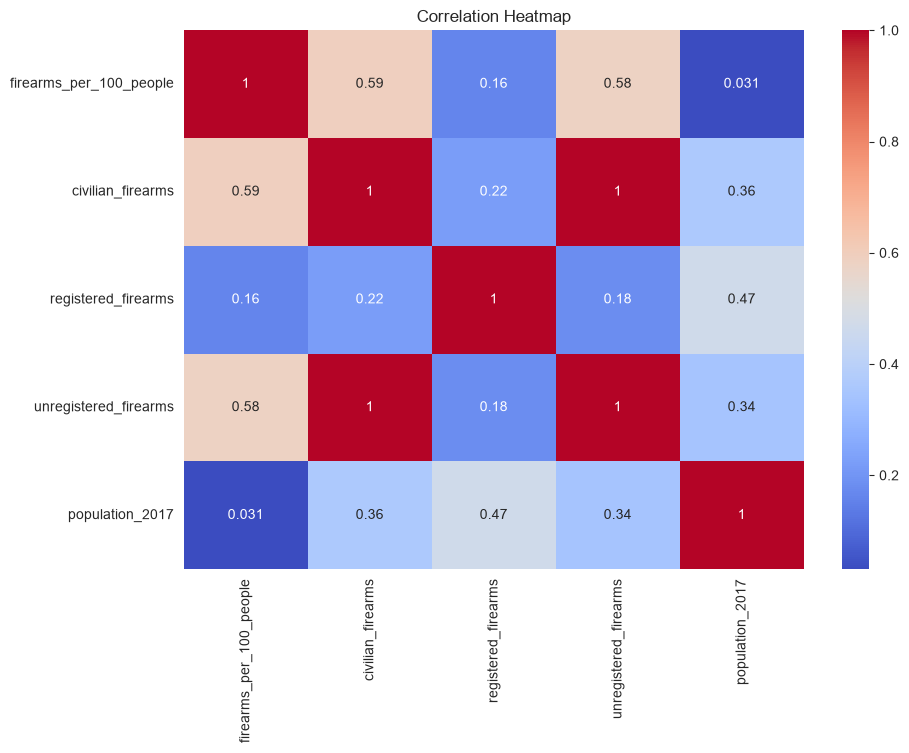

In [27]:
plt.figure(figsize=(10,7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

##  Population vs Civilian Firearms

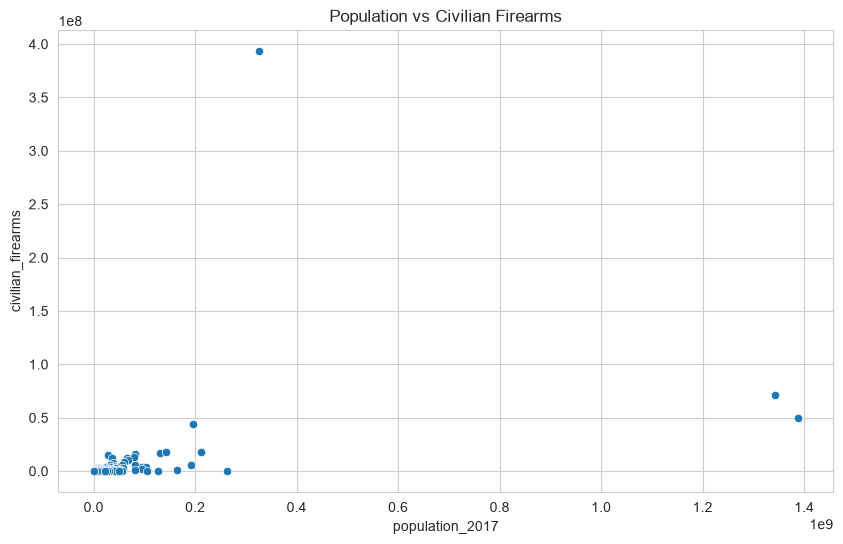

In [28]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="population_2017",
    y="civilian_firearms",
    data=df
)

plt.title("Population vs Civilian Firearms")

plt.show()

### Population vs Firearms Per 100 People

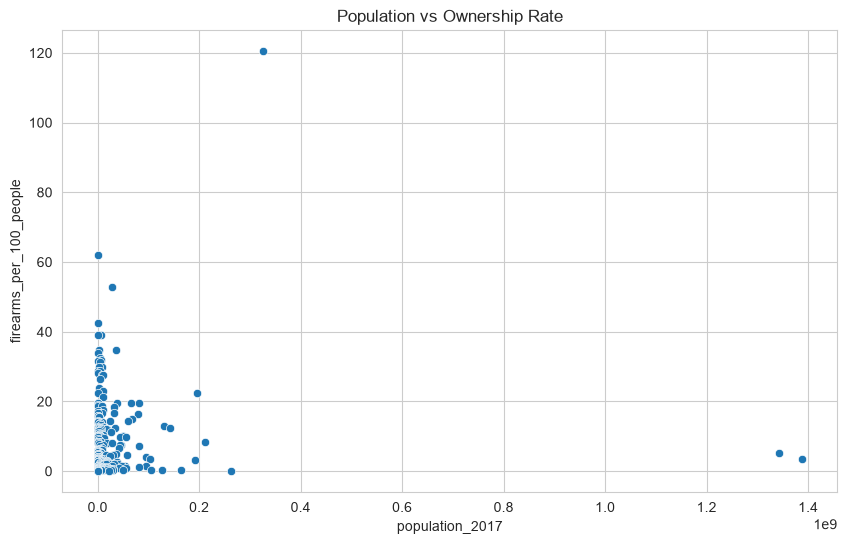

In [29]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="population_2017",
    y="firearms_per_100_people",
    data=df
)

plt.title("Population vs Ownership Rate")

plt.show()

## Distribution Analysis

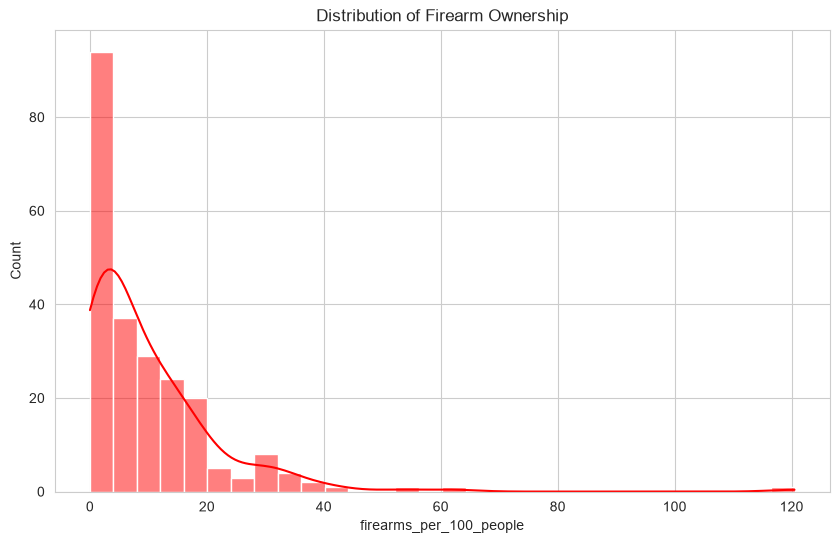

In [30]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["firearms_per_100_people"],
    bins=30,
    kde=True,
    color='red'
)

plt.title("Distribution of Firearm Ownership")

plt.show()

## Boxplot Detection of Outliers

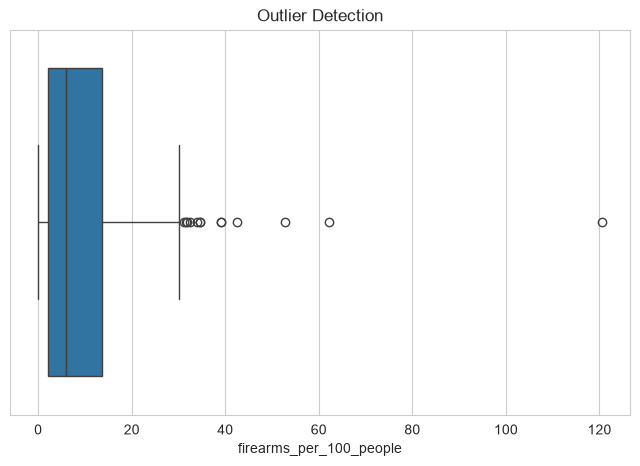

In [31]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["firearms_per_100_people"]
)

plt.title("Outlier Detection")

plt.show()


## Country Clustering (Unsupervised ML)

In [32]:
cluster_df = df[
    [
        "firearms_per_100_people",
        "civilian_firearms",
        "population_2017"
    ]
]

Scaling:

In [33]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    cluster_df
)

Elbow Method

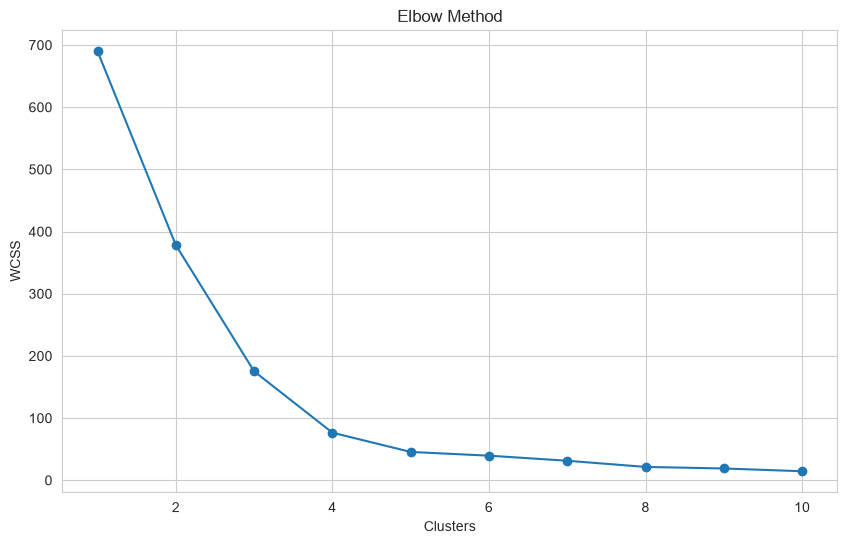

In [34]:
wcss=[]

for i in range(1,11):

    km = KMeans(
        n_clusters=i,
        random_state=42
    )

    km.fit(scaled_data)

    wcss.append(km.inertia_)

plt.plot(
    range(1,11),
    wcss,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Clusters")
plt.ylabel("WCSS")

plt.show()

### KMeans Clustering

In [35]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

df["Cluster"] = kmeans.fit_predict(
    scaled_data
)

## Cluster Visualization

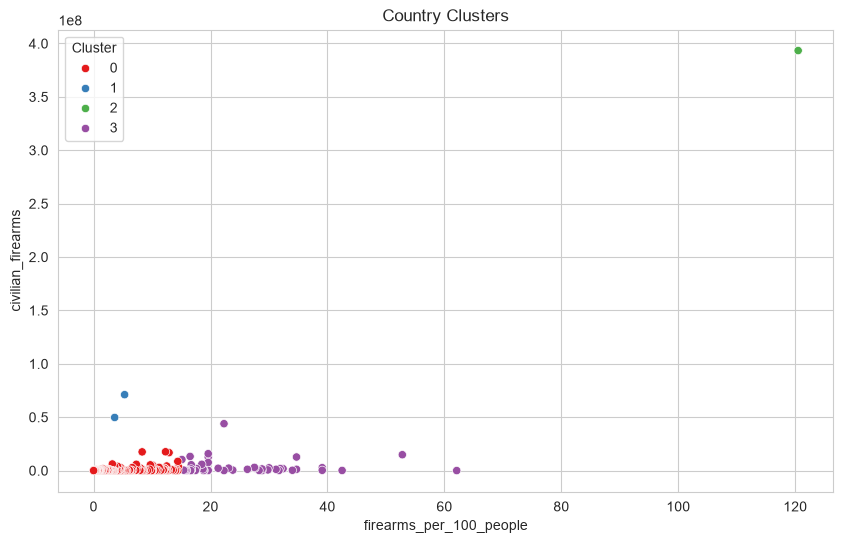

In [36]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="firearms_per_100_people",
    y="civilian_firearms",
    hue="Cluster",
    palette="Set1",
    data=df
)

plt.title("Country Clusters")

plt.show()

## Cluster Summary

In [37]:
df.groupby("Cluster")[[
    "firearms_per_100_people",
    "civilian_firearms",
    "population_2017"
]].mean()

,firearms_per_100_people,civilian_firearms,population_2017
Cluster,,,
0,5.067062,9.426573e+05,2.065575e+07
1,4.450000,6.041800e+07,1.365373e+09
2,120.500000,3.933470e+08,3.264740e+08
3,24.894000,3.557881e+06,1.609584e+07


## Export Final Dataset

In [38]:
df.to_csv(
    "firearms_analysis_output.csv",
    index=False
)

Executive Insights
Key Findings
The United States dominates firearm ownership globally.
Several low-population countries exhibit very high firearms-per-capita ratios.
South Asia contains large absolute numbers of firearms because of population size.
Considerable differences exist between registered and unregistered ownership across countries.
Population size alone does not explain firearm ownership rates.
Clustering reveals distinct groups of countries based on ownership intensity and firearm volume.

Global Civilian Firearms Analysis
Overview
This project explores worldwide civilian firearm ownership patterns using the Small Arms Survey 2017 dataset.

Objectives
Analyze firearm ownership by country
Compare regional trends
Examine registered vs unregistered firearms
Perform correlation analysis
Build K-Means country clusters
Tools Used
Python
Pandas
NumPy
Matplotlib
Seaborn
Scikit-Learn
Key Insights
United States exhibits the highest firearm ownership rate.
Significant regional variation exists in firearm ownership.
Strong relationship observed between civilian and unregistered firearms.
Countries can be grouped into ownership clusters using machine learning.
Machine Learning
Unsupervised Learning:

K-Means Clustering
Dataset
Global Gun Violence & Civilian Firearms Dataset (2017)

